# Conditions météorologiques et régularité des TGV en France

## 1. Introduction
(à rédiger)

### Chargement des bibliothèques et des fonctions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Récupération des données
from chargement_sncf import charger_sncf
from chargement_gares import charger_gares

# Préparation des données SNCF
from preparation_sncf import (
    lister_gares,
    filtrer_liaisons_francaises,
    construire_correspondances,
    ajouter_departements
)

# 2. Analyse de la régularité des TGV

## 2.1. Récupération et préparation des données SNCF


Les données ferroviaires proviennent du jeu de données *Régularité mensuelle TGV*, disponible sur la plateforme Open Data de la SNCF. Elles renseignent, pour chaque liaison et chaque mois, le nombre de trains prévus, les annulations et différents indicateurs de retard.

Afin d'automatiser la collecte et d'assurer la reproductibilité du projet, les données sont récupérées directement depuis l'API SNCF au moyen de requêtes HTTP, sans téléchargement manuel des fichiers. La période étudiée s'étend de **janvier 2018 à septembre 2026**.


In [2]:
# Récupération des données SNCF
df_sncf_brut = charger_sncf()

print("Dimensions de la base initiale :", df_sncf_brut.shape)
display(df_sncf_brut.head())

Dimensions de la base initiale : (12907, 26)


,date,service,gare_depart,gare_arrivee,duree_moyenne,nb_train_prevu,nb_annulation,commentaire_annulation,nb_train_depart_retard,retard_moyen_depart,...,nb_train_retard_sup_15,retard_moyen_trains_retard_sup15,nb_train_retard_sup_30,nb_train_retard_sup_60,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs
0,2018-01-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386


### Exploration des gares

Avant de définir le périmètre géographique de notre étude, nous examinons les gares présentes dans la base initiale.

Cette exploration permet d'identifier les éventuelles gares étrangères, ainsi que les valeurs manquantes ou les appellations particulières qui pourraient nécessiter un traitement.

In [3]:
# Exploration des gares
gares = lister_gares(df_sncf_brut)

print("Nombre de gares distinctes :", len(gares))
print("\nListe des gares :")
print(gares)

# Analyse des valeurs manquantes
valeurs_manquantes = pd.DataFrame({
    "Nombre de valeurs manquantes": df_sncf_brut.isna().sum(),
    "Pourcentage (%)": df_sncf_brut.isna().mean() * 100
})

display(
    valeurs_manquantes
    .sort_values("Nombre de valeurs manquantes", ascending=False)
    .round(2)
)

Nombre de gares distinctes : 59

Liste des gares :
['AIX EN PROVENCE TGV', 'ANGERS SAINT LAUD', 'ANGOULEME', 'ANNECY', 'ARRAS', 'AVIGNON TGV', 'BARCELONA', 'BELLEGARDE (AIN)', 'BESANCON FRANCHE COMTE TGV', 'BORDEAUX ST JEAN', 'BREST', 'CHAMBERY CHALLES LES EAUX', 'DIJON VILLE', 'DOUAI', 'DUNKERQUE', 'FRANCFORT', 'GENEVE', 'GRENOBLE', 'ITALIE', 'LA ROCHELLE VILLE', 'LAUSANNE', 'LAVAL', 'LE CREUSOT MONTCEAU MONTCHANIN', 'LE MANS', 'LILLE', 'LYON PART DIEU', 'MACON LOCHE', 'MADRID', 'MARNE LA VALLEE', 'MARSEILLE ST CHARLES', 'METZ', 'MONTPELLIER', 'MULHOUSE VILLE', 'NANCY', 'NANTES', 'NICE VILLE', 'NIMES', 'PARIS EST', 'PARIS LYON', 'PARIS MONTPARNASSE', 'PARIS NORD', 'PARIS VAUGIRARD', 'PERPIGNAN', 'POITIERS', 'QUIMPER', 'REIMS', 'RENNES', 'SAINT ETIENNE CHATEAUCREUX', 'ST MALO', 'ST PIERRE DES CORPS', 'STRASBOURG', 'STUTTGART', 'TOULON', 'TOULOUSE MATABIAU', 'TOURCOING', 'TOURS', 'VALENCE ALIXAN TGV', 'VANNES', 'ZURICH']


,Nombre de valeurs manquantes,Pourcentage (%)
commentaire_annulation,12907,100.00
commentaire_retards_depart,12907,100.00
commentaires_retard_arrivee,12209,94.59
gare_depart,0,0.00
service,0,0.00
gare_arrivee,0,0.00
nb_train_prevu,0,0.00
nb_annulation,0,0.00
duree_moyenne,0,0.00
date,0,0.00


L'exploration de la base révèle **59 appellations de gares distinctes**, dont huit correspondent à des destinations étrangères. Concernant les valeurs manquantes, seules trois variables de commentaires sont concernées. Ces variables n'étant pas utilisées dans notre analyse, aucune imputation n'est nécessaire.

Afin de conserver un périmètre cohérent avec les données météorologiques françaises, nous excluons les liaisons dont la gare de départ ou d'arrivée se situe à l'étranger.

In [4]:
# Conservation des liaisons françaises
df_sncf_fr = filtrer_liaisons_francaises(df_sncf_brut)

print("Observations initiales :", len(df_sncf_brut))
print("Observations conservées :", len(df_sncf_fr))

Observations initiales : 12907
Observations conservées : 11357


## 2.2. Analyse descriptive de la régularité des TGV

### 2.2.1. Statistiques descriptives des données SNCF

Nous examinons les principales caractéristiques des liaisons ferroviaires : le nombre de trains prévus, les annulations, les retards à l'arrivée et la durée moyenne des trajets.


In [5]:
# Statistiques descriptives des principales variables SNCF
variables_desc = [
    "nb_train_prevu",
    "nb_annulation",
    "nb_train_retard_arrivee",
    "duree_moyenne"
]

stats_desc = df_sncf_fr[variables_desc].describe().T

display(stats_desc.round(2))

,count,mean,std,min,25%,50%,75%,max
nb_train_prevu,11357.0,294.73,185.05,0.0,177.0,249.0,401.0,1104.0
nb_annulation,11357.0,8.90,23.01,0.0,0.0,2.0,7.0,297.0
nb_train_retard_arrivee,11357.0,41.74,33.12,0.0,18.0,34.0,57.0,376.0
duree_moyenne,11357.0,157.53,76.27,0.0,97.0,144.0,202.0,786.0


Les statistiques descriptives mettent en évidence une forte hétérogénéité entre les observations. Les annulations présentent notamment une distribution asymétrique à droite : leur moyenne (8,90) est nettement supérieure à leur médiane (2), avec un maximum de 297 annulations.

Par ailleurs, certaines observations présentent une durée moyenne de trajet nulle, ce qui nécessite un contrôle de cohérence.

In [6]:
# Contrôle des durées moyennes nulles
durees_nulles = df_sncf_fr[df_sncf_fr["duree_moyenne"] == 0]

print("Nombre de durées nulles :", len(durees_nulles))

print(
    "Durées nulles avec aucun train prévu :",
    (durees_nulles["nb_train_prevu"] == 0).sum()
)

print(
    "Durées nulles avec des trains prévus :",
    (durees_nulles["nb_train_prevu"] > 0).sum()
)

# Aperçu des observations concernées
display(
    durees_nulles[
        ["date", "gare_depart", "gare_arrivee",
         "nb_train_prevu", "nb_annulation", "duree_moyenne"]
    ].head(5)
)

Nombre de durées nulles : 46
Durées nulles avec aucun train prévu : 46
Durées nulles avec des trains prévus : 0


,date,gare_depart,gare_arrivee,nb_train_prevu,nb_annulation,duree_moyenne
3406,2020-04-01,PARIS MONTPARNASSE,ST MALO,0,8,0
3407,2020-04-01,PARIS MONTPARNASSE,TOURS,0,9,0
3409,2020-04-01,NANTES,STRASBOURG,0,2,0
3411,2020-04-01,PARIS NORD,DOUAI,0,12,0
3412,2020-04-01,DUNKERQUE,PARIS NORD,0,15,0


Les 46 observations présentant une durée moyenne nulle correspondent toutes à des situations où aucun train n'était prévu. Ces valeurs ne doivent donc pas être interprétées comme des durées de trajet réelles. Nous les conserverons dans la base, mais elles seront exclues des calculs nécessitant des circulations effectives positives.

### Construction des indicateurs de retard

Afin d'étudier la régularité des TGV, nous commençons par calculer le nombre de **circulations effectives**, correspondant au nombre de trains prévus diminué du nombre de trains annulés.

Cet indicateur servira de dénominateur pour calculer le taux de retard à l'arrivée. Nous vérifions d'abord sa cohérence, notamment la présence de valeurs nulles ou négatives.

In [7]:
# Calcul des circulations effectives
df_sncf_analyse = df_sncf_fr.copy()

df_sncf_analyse["circulations_effectives"] = (
    df_sncf_analyse["nb_train_prevu"]
    - df_sncf_analyse["nb_annulation"]
)

# Contrôle des valeurs nulles ou négatives
print(
    "Circulations effectives nulles ou négatives :",
    (df_sncf_analyse["circulations_effectives"] <= 0).sum()
)

Circulations effectives nulles ou négatives : 46


Nous identifions **46 observations pour lesquelles le nombre de circulations effectives est négatif**. Ces observations, concentrées en avril et mai 2020, correspondent à des situations où aucun train n'était prévu, mais des annulations étaient néanmoins renseignées.

Le taux de retard ne pouvant pas être calculé lorsque le nombre de circulations effectives est nul ou négatif, nous choisissons de **ne pas tenir compte de ces observations dans le calcul des taux**, sans les supprimer de la base initiale.

In [8]:
# Calcul du taux de retard à l'arrivée (en %)
df_sncf_analyse["taux_retard_arrivee"] = (
    100 * df_sncf_analyse["nb_train_retard_arrivee"]
    / df_sncf_analyse["circulations_effectives"].where(
        df_sncf_analyse["circulations_effectives"] > 0
    )
)

# Statistiques descriptives
display(df_sncf_analyse["taux_retard_arrivee"].describe().round(2))

print(
    "Taux non calculables :",
    df_sncf_analyse["taux_retard_arrivee"].isna().sum()
)

count    11311.00
mean        14.75
std          7.83
min          0.00
25%          9.45
50%         13.33
75%         18.49
max        100.00
Name: taux_retard_arrivee, dtype: float64

Taux non calculables : 46


La moyenne des taux de retard s'élève à 14,75 %, avec une médiane de 13,33 %. Toutefois, cette moyenne accorde le même poids à chaque observation, indépendamment du nombre de trains concernés.

Nous calculons donc également un taux global de retard, en rapportant le nombre total de trains en retard au nombre total de circulations effectives.

In [9]:
# Conservation des observations avec des circulations effectives positives
df_valides = df_sncf_analyse[
    df_sncf_analyse["circulations_effectives"] > 0
]

# Calcul du taux global de retard
taux_global = (
    100 * df_valides["nb_train_retard_arrivee"].sum()
    / df_valides["circulations_effectives"].sum()
)

print(f"Taux global de retard à l'arrivée : {taux_global:.2f} %")

Taux global de retard à l'arrivée : 14.60 %


### Évolution annuelle du taux de retard

Afin d'étudier l'évolution de la régularité des TGV, nous calculons le taux global de retard pour chaque année. Les données de 2026 étant disponibles uniquement jusqu'en septembre, nous limitons la comparaison aux mois de janvier à septembre pour l'ensemble des années, afin de conserver des périodes comparables.

In [10]:
# Préparation des données pour la comparaison annuelle
df_annuel = df_valides.copy()

df_annuel["date"] = pd.to_datetime(df_annuel["date"])
df_annuel["annee"] = df_annuel["date"].dt.year
df_annuel["mois"] = df_annuel["date"].dt.month

# Comparaison de janvier à septembre pour toutes les années
df_annuel = df_annuel[df_annuel["mois"] <= 9]

# Taux global de retard par année
evolution_annuelle = df_annuel.groupby("annee")[
    ["nb_train_retard_arrivee", "circulations_effectives"]
].sum()

evolution_annuelle["taux_retard"] = (
    100 * evolution_annuelle["nb_train_retard_arrivee"]
    / evolution_annuelle["circulations_effectives"]
)

display(evolution_annuelle.round(2))

,nb_train_retard_arrivee,circulations_effectives,taux_retard
annee,,,
2018,49025,267589,18.32
2019,36066,276842,13.03
2020,22971,188091,12.21
2021,26424,253319,10.43
2022,43895,308995,14.21
2023,43473,302033,14.39
2024,43323,315698,13.72
2025,43836,309468,14.16
2026,56021,302905,18.49


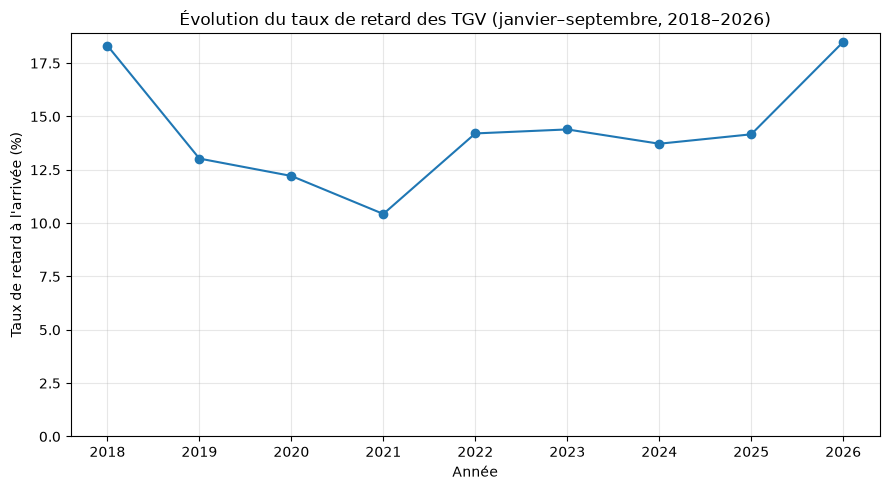

In [11]:
plt.figure(figsize=(9, 5))

plt.plot(
    evolution_annuelle.index,
    evolution_annuelle["taux_retard"],
    marker="o"
)

plt.title("Évolution du taux de retard des TGV (janvier–septembre, 2018–2026)")
plt.xlabel("Année")
plt.ylabel("Taux de retard à l'arrivée (%)")

plt.xticks(evolution_annuelle.index)
plt.ylim(bottom=0)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Le taux de retard à l'arrivée diminue entre 2018 et 2021, passant de **18,32 % à 10,43 %**. Il augmente ensuite et se stabilise autour de 14 % entre 2022 et 2025, avant d'atteindre **18,49 % en 2026**, son niveau le plus élevé sur la période étudiée.

Ces variations montrent que la régularité des TGV évolue sensiblement au cours du temps, sans permettre à ce stade d'en identifier les causes.

### Saisonnalité des retards

Nous étudions maintenant l'évolution du taux de retard selon le mois de l'année, afin d'identifier d'éventuelles variations saisonnières.

Pour cette analyse, nous retenons les années complètes de 2018 à 2025, afin que chaque mois soit observé sur le même nombre d'années.

In [12]:
# Préparation des données pour l'analyse mensuelle
df_mensuel = df_valides.copy()

df_mensuel["date"] = pd.to_datetime(df_mensuel["date"])
df_mensuel = df_mensuel[df_mensuel["date"].dt.year <= 2025]

df_mensuel["mois"] = df_mensuel["date"].dt.month

# Calcul du taux global de retard par mois
evolution_mensuelle = df_mensuel.groupby("mois")[
    ["nb_train_retard_arrivee", "circulations_effectives"]
].sum()

evolution_mensuelle["taux_retard"] = (
    100 * evolution_mensuelle["nb_train_retard_arrivee"]
    / evolution_mensuelle["circulations_effectives"]
)

display(evolution_mensuelle.round(2))

,nb_train_retard_arrivee,circulations_effectives,taux_retard
mois,,,
1,35067,254549,13.78
2,30451,237102,12.84
3,29444,240004,12.27
4,27188,210952,12.89
5,28092,235253,11.94
6,39864,249617,15.97
7,47347,267693,17.69
8,36964,265935,13.90
9,34596,260930,13.26


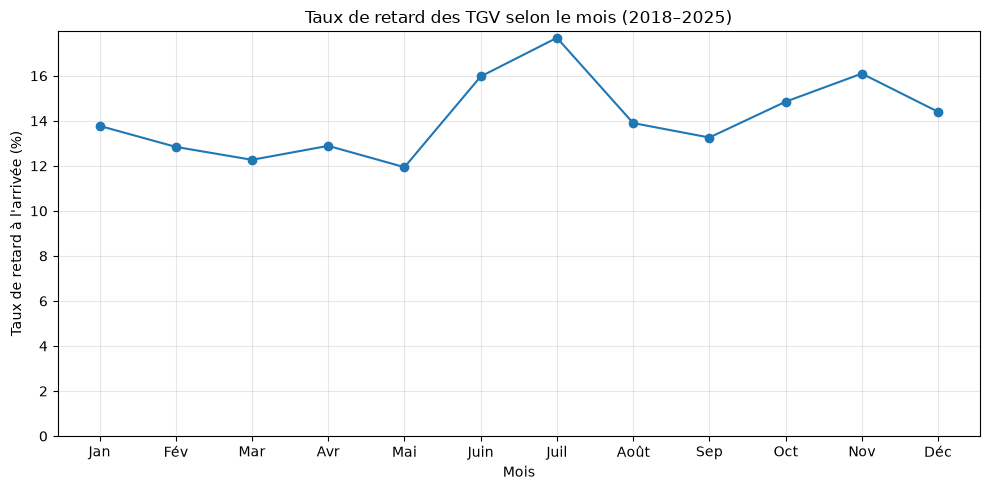

In [13]:
mois_noms = [
    "Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
    "Juil", "Août", "Sep", "Oct", "Nov", "Déc"
]

plt.figure(figsize=(10, 5))

plt.plot(
    evolution_mensuelle.index,
    evolution_mensuelle["taux_retard"],
    marker="o"
)

plt.title("Taux de retard des TGV selon le mois (2018–2025)")
plt.xlabel("Mois")
plt.ylabel("Taux de retard à l'arrivée (%)")

plt.xticks(range(1, 13), mois_noms)
plt.ylim(bottom=0)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Le taux de retard varie selon les mois de l'année. Sur la période 2018–2025, il est particulièrement élevé en **juillet (17,69 %)** et en **novembre (16,10 %)**, tandis que **mai présente le taux le plus faible (11,94 %)**.

Ces différences suggèrent l'existence de variations saisonnières, sans permettre d'en identifier les causes. Nous chercherons notamment à déterminer si certaines de ces variations sont associées aux conditions météorologiques.